# 01 · Kiểm tra chất lượng và phạm vi dữ liệu

> **Phạm vi: `analysis_only`.** Notebook đọc *full view* của dữ liệu thô để audit và hiểu bối cảnh.
> Không dùng nó để fit hay chọn mô hình. Mọi số bên dưới được tính lại mỗi lần chạy, không chép từ tài liệu.

**Mục tiêu.** Biết dữ liệu có gì, thiếu gì, và còn bao nhiêu event/issue sau khi chọn core view.

**Câu hỏi.**
1. Có bao nhiêu event và issue, độ dài lịch sử mỗi issue phân bố ra sao?
2. Chất lượng: role trống, bot, timestamp, dòng trùng, trùng thời điểm, thứ tự dòng?
3. Funnel raw → full → core: bao nhiêu event bị bỏ vì sau terminal hoặc vì nhiễu theo policy?
4. Ánh xạ action → activity phủ được bao nhiêu? Ca nào bị loại và vì sao?

**Đầu vào.** Một run trong `outputs/runs/<run_id>` (đã kiểm fingerprint) và CSV gốc trong `dataset/` (chỉ đọc).

In [1]:
# Khởi tạo: mở run đã kiểm fingerprint (biến môi trường JIRA_AD_RUN_DIR do `jira-ad notebooks` đặt).
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from jira_ad.analysis import open_run

pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 90
run = open_run()
print(run.header())

run_id      : 20261017T081309Z-930f8a85  (status: completed)
chọn run    : tự động: run hoàn tất mới nhất khớp configs/baseline.yaml hiện tại (đặt JIRA_AD_RUN_DIR để chọn run khác)
config_hash : 930f8a856d4a…  config: configs/experiments.yaml
split_hash  : a3999ae50439…  action_rules: 4a35ef7d0f48…
đầu vào     : dataset/TIeventlogBug.csv sha256=cda16f1c5c4a…; configs/actions.yaml sha256=4a35ef7d0f48…
seeds       : {'split': 42, 'model': 42, 'validation_mutation': 1042, 'test_mutation': 2042}  | cohort: bug  | methods: ['A_stats', 'B_ngrams', 'C_embedding', 'D_hybrid']


In [2]:
from jira_ad import plots
from jira_ad.data import audit_events, load_raw_events
from jira_ad.preprocess import load_action_rules, mapping_coverage, normalize_events

cfg = run.cfg
raw = load_raw_events(cfg.data, run.project_root)          # raw view, chỉ đọc (analysis_only)
rules = load_action_rules(cfg.preprocess.actions_path)
events = normalize_events(raw, cfg.preprocess, rules)      # full view đã chuẩn hóa
raw_audit = audit_events(raw)
prep = run.read_json("preprocess_audit.json")
print(f"Cohort `{cfg.data.cohort}`: {len(raw):,} dòng, {raw.case_id.nunique()} issue, nguồn {raw.source_file.iloc[0]}")

Cohort `bug`: 5,126 dòng, 161 issue, nguồn dataset/TIeventlogBug.csv


## 1. Quy mô và độ dài lịch sử

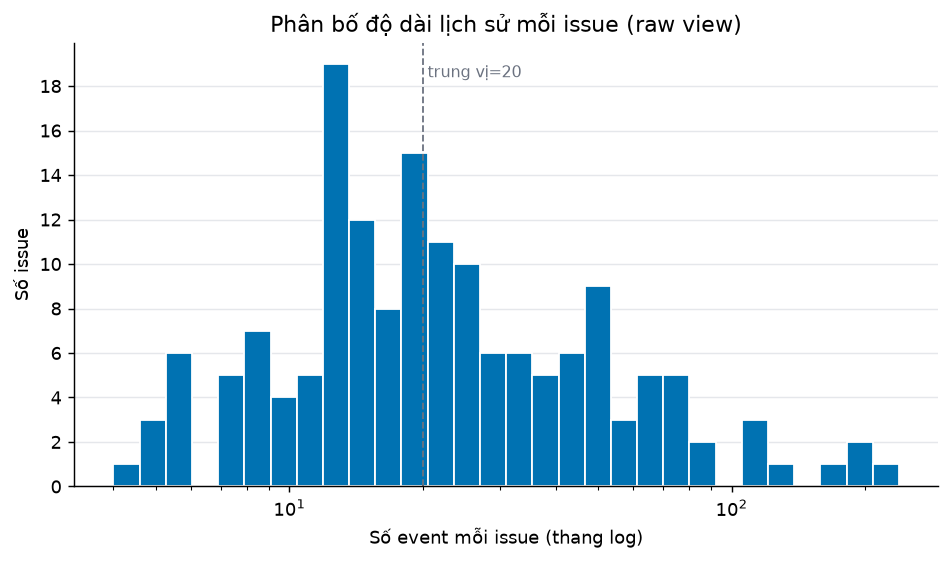

,events_per_issue
count,161.000
mean,31.839
std,35.432
min,4.000
25%,13.000
50%,20.000
75%,39.000
90%,65.000
max,239.000


In [3]:
per_case = raw.groupby("case_id").size()
fig = plots.plot_histogram(per_case, "Số event mỗi issue (thang log)",
                           "Phân bố độ dài lịch sử mỗi issue (raw view)", log_x=True)
_ = run.show(fig, "nb01_events_per_issue", per_case.rename("n_events").reset_index())
per_case.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).to_frame("events_per_issue")

## 2. Chất lượng dữ liệu

In [4]:
role_counts = raw_audit["role_counts"]
quality = pd.DataFrame([
    ("event (raw)", raw_audit["n_events"]),
    ("issue", raw_audit["n_cases"]),
    ("issue chỉ có 1 event", raw_audit["n_single_event_cases"]),
    ("event có role trống", raw_audit["n_blank_role"]),
    ("event role = unknown", role_counts.get("unknown", 0)),
    ("event do bot", raw_audit["n_role_bot"]),
    ("tỷ lệ event do bot", round(raw_audit["bot_share"], 4)),
    ("issue có dòng KHÔNG theo thứ tự thời gian", raw_audit["n_cases_needing_reorder"]),
    ("nhóm trùng thời điểm (cùng issue, cùng UTC)", raw_audit["n_tie_groups"]),
    ("event nằm trong nhóm trùng", raw_audit["n_events_in_ties"]),
    ("dòng trùng hệt", raw_audit["n_exact_duplicate_rows"]),
    ("số chuỗi action thô khác nhau", raw_audit["n_distinct_raw_actions"]),
], columns=["chỉ số", "giá trị"])
quality["giá trị"] = quality["giá trị"].map(lambda v: f"{v:,}" if isinstance(v, (int, np.integer)) else f"{v:.3f}")
run.save_table(quality, "nb01_quality")
quality

,chỉ số,giá trị
0,event (raw),5126.000
1,issue,161.000
2,issue chỉ có 1 event,0.000
3,event có role trống,15.000
4,event role = unknown,837.000
5,event do bot,2230.000
6,tỷ lệ event do bot,0.435
7,issue có dòng KHÔNG theo thứ tự thời gian,161.000
8,"nhóm trùng thời điểm (cùng issue, cùng UTC)",0.000
9,event nằm trong nhóm trùng,0.000


In [5]:
roles = pd.Series(role_counts, name="events").rename_axis("role").reset_index()
roles["role"] = roles["role"].replace("", "(trống)")
roles["share"] = roles["events"] / roles["events"].sum()
offsets = pd.Series(raw_audit["utc_offsets"], name="events").rename_axis("offset").reset_index()
run.save_table(roles, "nb01_roles")
display(roles)
display(offsets)
display(Markdown(
    f"Khoảng thời gian (UTC): **{raw_audit['timestamp_min_utc']}** → **{raw_audit['timestamp_max_utc']}**. "
    f"Có {len(offsets)} offset múi giờ khác nhau; mọi timestamp được đổi sang UTC trước khi sắp xếp."
))

,role,events,share
0,bot,2230,0.435
1,PO,1296,0.253
2,unknown,837,0.163
3,Eng,489,0.095
4,SQA,168,0.033
5,RTE,43,0.008
6,Integrator,21,0.004
7,(trống),15,0.003
8,Support/Mgr,11,0.002
9,PM,7,0.001


,offset,events
0,-0700,2779
1,-0800,2347


Khoảng thời gian (UTC): **2021-06-02T07:24:19.359+00:00** → **2022-08-09T12:30:44.411+00:00**. Có 2 offset múi giờ khác nhau; mọi timestamp được đổi sang UTC trước khi sắp xếp.

In [6]:
# Hướng thứ tự dòng trong file so với thời gian (bỏ dòng đầu của mỗi issue, thường là `Issue created`).
def direction(group):
    stamps = group.sort_values("source_row").timestamp_utc.iloc[1:]
    if stamps.is_monotonic_decreasing:
        return "giảm dần (mới → cũ)"
    return "tăng dần (cũ → mới)" if stamps.is_monotonic_increasing else "lẫn lộn"

directions = events.groupby("case_id").apply(direction, include_groups=False).value_counts()
first_is_create = events.sort_values("source_row").groupby("case_id").first().activity.eq("CREATE").sum()
display(directions.to_frame("số issue"))
display(Markdown(
    f"Dòng đầu của **{first_is_create}/{raw_audit['n_cases']}** issue là `Issue created`. "
    "Thứ tự dòng trong CSV không đáng tin để suy ra thứ tự thời gian; pipeline luôn sắp lại theo "
    "`(case_id, timestamp_utc, source_row)`. Nếu có trùng thời điểm, `source_row` chỉ là quy tắc kỹ thuật, "
    "không phải thứ tự nghiệp vụ đã biết."
))

,số issue
giảm dần (mới → cũ),161


Dòng đầu của **161/161** issue là `Issue created`. Thứ tự dòng trong CSV không đáng tin để suy ra thứ tự thời gian; pipeline luôn sắp lại theo `(case_id, timestamp_utc, source_row)`. Nếu có trùng thời điểm, `source_row` chỉ là quy tắc kỹ thuật, không phải thứ tự nghiệp vụ đã biết.

## 3. Raw → full → core (số liệu raw và core xuất riêng)

In [7]:
def view_row(label, events_, cases, missing, unknown, bot):
    return {"view": label, "events": events_, "issues": cases, "role trống": missing,
            "role unknown": unknown, "event bot": bot}

full, core_v = prep["full_view"], prep["core_view"]
views = pd.DataFrame([
    view_row("raw (CSV)", raw_audit["n_events"], raw_audit["n_cases"], raw_audit["n_blank_role"],
             role_counts.get("unknown", 0), raw_audit["n_role_bot"]),
    view_row("full (đã chuẩn hóa)", full["n_events"], full["n_cases"], full["n_missing_role_events"],
             full["n_unknown_role_events"], full["n_bot_events"]),
    view_row("core (mô hình dùng)", core_v["n_events"], core_v["n_cases"], core_v["n_missing_role_events"],
             core_v["n_unknown_role_events"], core_v["n_bot_events"]),
])
run.save_table(views, "nb01_views")
views

,view,events,issues,role trống,role unknown,event bot
0,raw (CSV),5126,161,15,837,2230
1,full (đã chuẩn hóa),5126,161,15,837,2230
2,core (mô hình dùng),3258,161,15,832,431


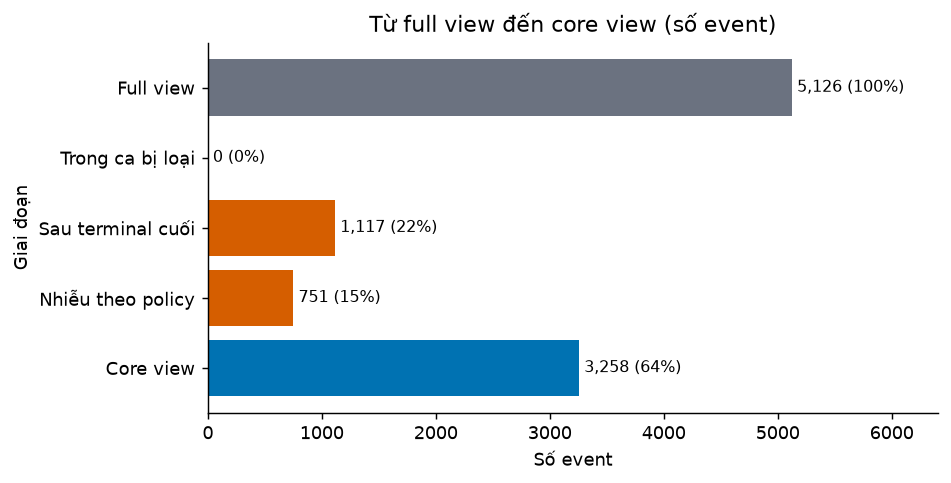

In [8]:
funnel = prep["funnel"]
assert funnel["n_events_full"] == (funnel["n_events_in_excluded_cases"] + funnel["n_events_post_terminal"]
                                   + funnel["n_events_dropped_noise"] + funnel["n_events_core"])
fig = plots.plot_funnel(funnel)
_ = run.show(fig, "nb01_funnel", pd.Series(funnel, name="n_events").rename_axis("stage").reset_index())

In [9]:
# Đối chiếu độc lập với artifact: tự tính số event sau status terminal cuối từ full view.
terminal = set(cfg.preprocess.terminal_statuses)
post_parts = []
for case_id, group in events.groupby("case_id"):
    positions = np.flatnonzero(group["has_status_update"].to_numpy())
    if positions.size and group["status_value"].iloc[positions[-1]] in terminal:
        post_parts.append(group.iloc[positions[-1] + 1:])
post = pd.concat(post_parts) if post_parts else events.iloc[0:0]
assert len(post) == funnel["n_events_post_terminal"], "notebook và preprocess_audit.json phải khớp"
top_post = (post.groupby("raw_action").size().sort_values(ascending=False).head(8)
            .rename("events").rename_axis("raw_action").reset_index())
bot_share_post = post["is_bot"].mean() if len(post) else float("nan")
display(top_post)
display(Markdown(
    f"**{len(post):,}** event ({len(post) / len(events):.1%} full view) nằm sau status terminal cuối của "
    f"**{post.case_id.nunique()}** issue; **{bot_share_post:.0%}** trong số đó do bot. Khớp `preprocess_audit.json`."
))

,raw_action,events
0,update RemoteIssueLink,1025
1,add RemoteIssueLink to Commit,18
2,edit description,11
3,add Fix Version,10
4,add Epic Link,8
5,edit IssueParentAssociation,8
6,add Story Points,7
7,add link to relates to,5


**1,117** event (21.8% full view) nằm sau status terminal cuối của **63** issue; **94%** trong số đó do bot. Khớp `preprocess_audit.json`.

## 4. Ca bị loại và ánh xạ action

In [10]:
exclusions = run.read_csv("exclusions.csv")
event_exclusions = run.read_csv("tables/event_exclusions.csv")
display(event_exclusions)
if exclusions.empty:
    display(Markdown(
        f"Không ca nào bị loại ở bước chọn core view: cả **{core_v['n_cases']}** issue đều kết thúc ở một status terminal "
        f"({', '.join(sorted(terminal))}). Nhánh loại ‘status cuối không terminal’ chưa được dữ liệu thật kiểm chứng."
    ))
else:
    display(exclusions.groupby("reason").agg(cases=("case_id", "size"), events=("n_events", "sum")))

,stage,rule,n_events,n_cases
0,post_terminal,after_final_terminal_status,1117,63
1,noise_policy,drop_generic_external_link_updates:UPDATE_EXTERNAL_LINK,751,55


Không ca nào bị loại ở bước chọn core view: cả **161** issue đều kết thúc ở một status terminal (DONE, Rejected). Nhánh loại ‘status cuối không terminal’ chưa được dữ liệu thật kiểm chứng.

In [11]:
coverage = mapping_coverage(events)
fallback = coverage[coverage.is_fallback]
run.save_table(coverage, "nb01_mapping_coverage")
display(Markdown(
    f"**{len(coverage)}** chuỗi action thô → **{events.activity.nunique()}** activity; "
    f"**{len(fallback)}** chuỗi rơi vào `OTHER_ACTION` ({int(fallback.n_events.sum())} event). "
    f"**{int((events.secondary_changes != '').sum())}** event có thay đổi phụ (nhiều field trong một dòng, giữ một event)."
))
coverage[~coverage.is_fallback].head(12)[["raw_action", "activity", "secondary_changes", "n_events", "n_cases"]]

**99** chuỗi action thô → **50** activity; **0** chuỗi rơi vào `OTHER_ACTION` (0 event). **314** event có thay đổi phụ (nhiều field trong một dòng, giữ một event).

,raw_action,activity,secondary_changes,n_events,n_cases
0,update RemoteIssueLink,UPDATE_EXTERNAL_LINK,,1776,55
1,edit description,EDIT_DESCRIPTION,,368,123
2,add RemoteIssueLink to Commit,LINK_COMMIT,,360,55
3,add link to relates to,ADD_ISSUE_LINK,,325,154
4,Issue created,CREATE,,161,161
5,update Backlog Classification to Technical Debt,UPDATE_BACKLOG_CLASSIFICATION,,128,127
6,remove assignee,REMOVE_ASSIGNEE,,127,121
7,edit IssueParentAssociation,EDIT_ISSUEPARENTASSOCIATION,,122,83
8,"update project to TI-TI, edit Key",UPDATE_PROJECT,EDIT_KEY,117,117
9,update status to INVESTIGATED,STATUS_INVESTIGATED,,114,106


## Nhận xét (sinh từ số liệu của run này)

In [12]:
lines = [
    f"- **Quy mô:** {raw_audit['n_events']:,} event của {raw_audit['n_cases']} issue; trung vị {per_case.median():.0f} event/issue, "
    f"lớn nhất {per_case.max()}.",
    f"- **Role:** {raw_audit['n_blank_role']} event trống, {role_counts.get('unknown', 0)} `unknown` "
    f"({role_counts.get('unknown', 0) / raw_audit['n_events']:.0%}), {raw_audit['bot_share']:.0%} do bot ⇒ đặc trưng role chỉ dựa được vào phần còn lại.",
    f"- **Thứ tự:** {raw_audit['n_cases_needing_reorder']}/{raw_audit['n_cases']} issue phải sắp lại; trùng thời điểm: {raw_audit['n_tie_groups']} nhóm.",
    f"- **Core view:** giữ {core_v['n_events']:,}/{funnel['n_events_full']:,} event ({core_v['n_events'] / funnel['n_events_full']:.0%}); "
    f"bỏ {funnel['n_events_post_terminal']:,} sau terminal và {funnel['n_events_dropped_noise']:,} nhiễu theo policy `{prep['noise_policy']}`.",
    f"- **Terminal cuối:** {core_v['terminal_status_counts']}; {prep['reopen']['n_cases_with_reopen']} issue có reopen trước mốc cuối (vẫn giữ trong core).",
]
display(Markdown("\n".join(lines)))

- **Quy mô:** 5,126 event của 161 issue; trung vị 20 event/issue, lớn nhất 239.
- **Role:** 15 event trống, 837 `unknown` (16%), 44% do bot ⇒ đặc trưng role chỉ dựa được vào phần còn lại.
- **Thứ tự:** 161/161 issue phải sắp lại; trùng thời điểm: 0 nhóm.
- **Core view:** giữ 3,258/5,126 event (64%); bỏ 1,117 sau terminal và 751 nhiễu theo policy `drop_generic_external_link_updates`.
- **Terminal cuối:** {'DONE': 83, 'Rejected': 78}; 8 issue có reopen trước mốc cuối (vẫn giữ trong core).

## Giả thuyết và giới hạn

- Dữ liệu gồm *issue đã kết thúc*; kết luận chỉ áp dụng cho ca có kết thúc quan sát được (đánh giá hồi cứu), không cho phát hiện sớm.
- Nhiều event do bot sau terminal có thể là hoạt động tự động bình thường; việc bỏ chúng là **lựa chọn thiết kế**, không phải khẳng định chúng vô nghĩa.
- Chuỗi trạng thái dồn dập trong vài giây (xem notebook 02) có thể là thao tác thử/migration; chưa đủ dữ liệu để nói đó là quy trình thật.
- Notebook này không có nhãn bất thường; ‘hiếm’ không có nghĩa là ‘sai’.